<a href="https://colab.research.google.com/github/romandudarets/Data-Analysis-University/blob/main/%D0%9B%D1%808_%D0%94%D1%83%D0%B4%D0%B0%D1%80%D0%B5%D1%86%D1%8C_4_9_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

sns.set(style="whitegrid")

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [2]:
iris = load_iris()
iris_df = pd.DataFrame(iris.data, columns=iris.feature_names)
display(iris_df.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

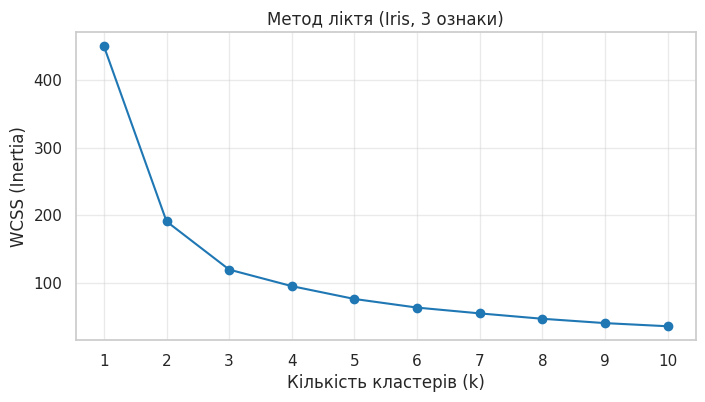

In [3]:
X_iris = iris_df.iloc[:, :3]

scaler_iris = StandardScaler()
X_iris_scaled = scaler_iris.fit_transform(X_iris)

wcss_iris = []
k_range_elbow = range(1, 11)

for k in k_range_elbow:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_iris_scaled)
    wcss_iris.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_range_elbow, wcss_iris, marker="o", linestyle="-", color="tab:blue")
plt.title("Метод ліктя (Iris, 3 ознаки)")
plt.xlabel("Кількість кластерів (k)")
plt.ylabel("WCSS (Inertia)")
plt.xticks(k_range_elbow)
plt.grid(True, alpha=0.4)
plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

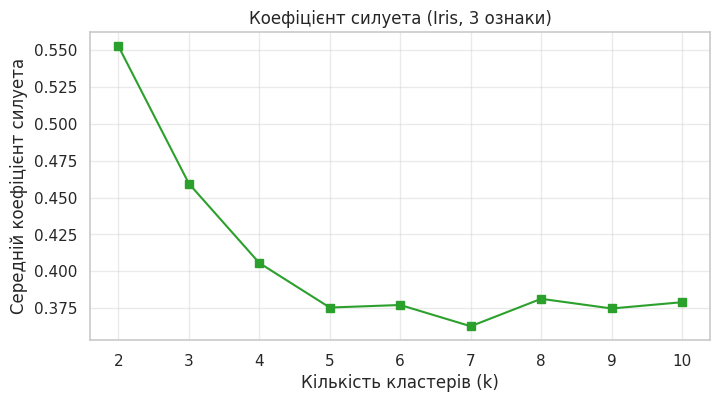

In [4]:
sil_scores_iris = []
k_range_sil = range(2, 11)

for k in k_range_sil:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_iris_scaled)
    sil_scores_iris.append(silhouette_score(X_iris_scaled, labels))

plt.figure(figsize=(8, 4))
plt.plot(k_range_sil, sil_scores_iris, marker="s", linestyle="-", color="tab:green")
plt.title("Коефіцієнт силуета (Iris, 3 ознаки)")
plt.xlabel("Кількість кластерів (k)")
plt.ylabel("Середній коефіцієнт силуета")
plt.xticks(k_range_sil)
plt.grid(True, alpha=0.4)
plt.show()

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

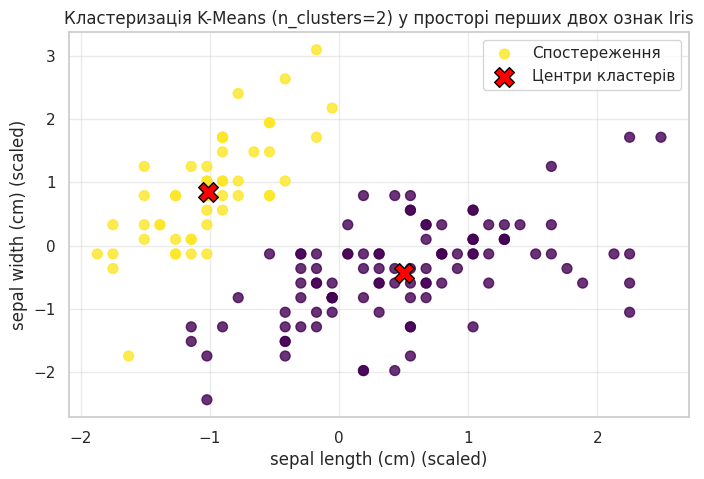

In [5]:
kmeans_iris_2 = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters_iris_2 = kmeans_iris_2.fit_predict(X_iris_scaled)
centers_iris_2 = kmeans_iris_2.cluster_centers_

plt.figure(figsize=(8, 5))
plt.scatter(
    X_iris_scaled[:, 0],
    X_iris_scaled[:, 1],
    c=clusters_iris_2,
    cmap="viridis",
    s=50,
    alpha=0.8,
    label="Спостереження"
)
plt.scatter(
    centers_iris_2[:, 0],
    centers_iris_2[:, 1],
    c="red",
    marker="X",
    s=200,
    edgecolors="black",
    label="Центри кластерів"
)
plt.title("Кластеризація K-Means (n_clusters=2) у просторі перших двох ознак Iris")
plt.xlabel(f"{X_iris.columns[0]} (scaled)")
plt.ylabel(f"{X_iris.columns[1]} (scaled)")
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Короткий висновок до завдання 1:** На графіку методу ліктя найрізкіше зменшення внутрішньокластерної суми квадратів (WCSS) відбувається при переході від $k=1$ до $k=2$ та $k=3$, а на графіку коефіцієнта силуета абсолютний максимум досягається при $k=2$. Два кластери обрано тому, що один вид ірисів (Iris setosa) лінійно та чітко відокремлюється від двох інших (versicolor і virginica), які частково перекриваються у просторі ознак — такий вибір повністю узгоджується з максимумом коефіцієнта силуета та першим виразним згином на графіку ліктя.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [7]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [8]:
# Вивід даних з файлу
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [9]:
print("Назви стовпців:")
print(list(df.columns))

Назви стовпців:
['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [11]:
print("Пропущені значення у кожному стовпці:")
print(df.isna().sum())

Пропущені значення у кожному стовпці:
StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [12]:
print("Кількість дублікатів:", df.duplicated().sum())

Кількість дублікатів: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [13]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
StudentID,2392.0,2196.500000,690.655244,1001.000000,1598.750000,2196.500000,2794.250000,3392.000000
Age,2392.0,16.468645,1.123798,15.000000,15.000000,16.000000,17.000000,18.000000
Gender,2392.0,0.510870,0.499986,0.000000,0.000000,1.000000,1.000000,1.000000
Ethnicity,2392.0,0.877508,1.028476,0.000000,0.000000,0.000000,2.000000,3.000000
ParentalEducation,2392.0,1.746237,1.000411,0.000000,1.000000,2.000000,2.000000,4.000000
StudyTimeWeekly,2392.0,9.771992,5.652774,0.001057,5.043079,9.705363,14.408410,19.978094
Absences,2392.0,14.541388,8.467417,0.000000,7.000000,15.000000,22.000000,29.000000
Tutoring,2392.0,0.301421,0.458971,0.000000,0.000000,0.000000,1.000000,1.000000
ParentalSupport,2392.0,2.122074,1.122813,0.000000,1.000000,2.000000,3.000000,4.000000
Extracurricular,2392.0,0.383361,0.486307,0.000000,0.000000,0.000000,1.000000,1.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [15]:
X = df.drop(columns=["GradeClass", "StudentID"])
y = df["GradeClass"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler_cls = StandardScaler()
X_train_scaled = scaler_cls.fit_transform(X_train)
X_test_scaled = scaler_cls.transform(X_test)

print("X_train_scaled:", X_train_scaled.shape, "| X_test_scaled:", X_test_scaled.shape)

X_train_scaled: (1913, 13) | X_test_scaled: (479, 13)


### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [16]:
rf_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid=rf_param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)
rf_grid.fit(X_train_scaled, y_train)

rf_best = rf_grid.best_estimator_
rf_test_acc = accuracy_score(y_test, rf_best.predict(X_test_scaled))

print("Random Forest — найкращі параметри:", rf_grid.best_params_)
print(f"Random Forest — середня CV accuracy: {rf_grid.best_score_:.4f}")
print(f"Random Forest — тестова accuracy:    {rf_test_acc:.4f}")

Random Forest — найкращі параметри: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200}
Random Forest — середня CV accuracy: 0.9211
Random Forest — тестова accuracy:    0.9102


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [17]:
lr_param_grid = {
    "C": [0.1, 1.0, 10.0],
    "penalty": ["l1", "l2"],
    "solver": ["saga"],
    "max_iter": [1000],
}

lr_grid = GridSearchCV(
    LogisticRegression(random_state=42),
    param_grid=lr_param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)
lr_grid.fit(X_train_scaled, y_train)

lr_best = lr_grid.best_estimator_
lr_test_acc = accuracy_score(y_test, lr_best.predict(X_test_scaled))

print("Logistic Regression — найкращі параметри:", lr_grid.best_params_)
print(f"Logistic Regression — середня CV accuracy: {lr_grid.best_score_:.4f}")
print(f"Logistic Regression — тестова accuracy:    {lr_test_acc:.4f}")

Logistic Regression — найкращі параметри: {'C': 0.1, 'max_iter': 1000, 'penalty': 'l1', 'solver': 'saga'}
Logistic Regression — середня CV accuracy: 0.8024
Logistic Regression — тестова accuracy:    0.8184


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [18]:
svm_param_grid = {
    "C": [0.5, 1.0, 5.0, 10.0],
    "kernel": ["rbf", "linear"],
    "gamma": ["scale", "auto"],
}

svm_grid = GridSearchCV(
    SVC(random_state=42),
    param_grid=svm_param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)
svm_grid.fit(X_train_scaled, y_train)

svm_best = svm_grid.best_estimator_
svm_test_acc = accuracy_score(y_test, svm_best.predict(X_test_scaled))

print("SVM — найкращі параметри:", svm_grid.best_params_)
print(f"SVM — середня CV accuracy: {svm_grid.best_score_:.4f}")
print(f"SVM — тестова accuracy:    {svm_test_acc:.4f}")

SVM — найкращі параметри: {'C': 0.5, 'gamma': 'scale', 'kernel': 'linear'}
SVM — середня CV accuracy: 0.8531
SVM — тестова accuracy:    0.8539


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [19]:
cls_results = pd.DataFrame([
    {
        "Model": "Random Forest",
        "CV Accuracy": rf_grid.best_score_,
        "Test Accuracy": rf_test_acc,
        "Estimator": rf_best
    },
    {
        "Model": "Logistic Regression",
        "CV Accuracy": lr_grid.best_score_,
        "Test Accuracy": lr_test_acc,
        "Estimator": lr_best
    },
    {
        "Model": "SVM",
        "CV Accuracy": svm_grid.best_score_,
        "Test Accuracy": svm_test_acc,
        "Estimator": svm_best
    }
]).sort_values(by="CV Accuracy", ascending=False).reset_index(drop=True)

display(cls_results[["Model", "CV Accuracy", "Test Accuracy"]])

best_cls_row = cls_results.iloc[0]
print(f"\nНайкраща модель за CV-точністю: {best_cls_row['Model']} (CV Accuracy = {best_cls_row['CV Accuracy']:.4f})")
print("\nClassification Report на тестових даних (для моделі, обраної за CV):")
y_test_pred_best = best_cls_row["Estimator"].predict(X_test_scaled)
print(classification_report(y_test, y_test_pred_best, digits=4))

,Model,CV Accuracy,Test Accuracy
0,Random Forest,0.921071,0.910230
1,SVM,0.853115,0.853862
2,Logistic Regression,0.802411,0.818372



Найкраща модель за CV-точністю: Random Forest (CV Accuracy = 0.9211)

Classification Report на тестових даних (для моделі, обраної за CV):
              precision    recall  f1-score   support

         0.0     1.0000    0.2857    0.4444        21
         1.0     0.8214    0.8519    0.8364        54
         2.0     0.8916    0.9487    0.9193        78
         3.0     0.8916    0.8916    0.8916        83
         4.0     0.9402    0.9712    0.9555       243

    accuracy                         0.9102       479
   macro avg     0.9090    0.7898    0.8094       479
weighted avg     0.9131    0.9102    0.9027       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

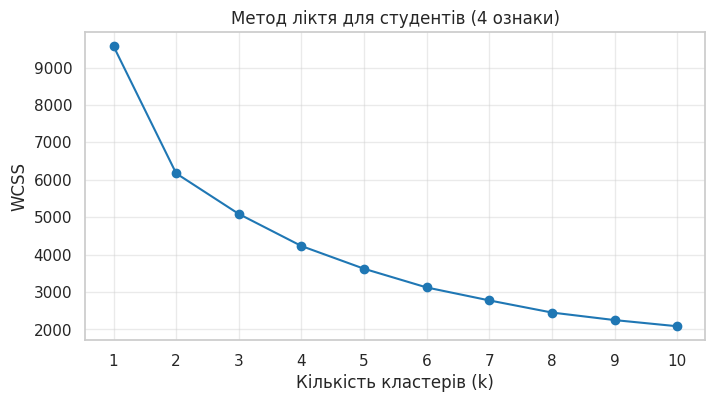

In [20]:
cluster_cols = ["Age", "StudyTimeWeekly", "Absences", "GPA"]
X_stud_4 = df[cluster_cols]

scaler_stud_4 = StandardScaler()
X_stud_4_scaled = scaler_stud_4.fit_transform(X_stud_4)

wcss_stud = []
k_vals_1_10 = range(1, 11)

for k in k_vals_1_10:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_stud_4_scaled)
    wcss_stud.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_vals_1_10, wcss_stud, marker="o", color="tab:blue")
plt.title("Метод ліктя для студентів (4 ознаки)")
plt.xlabel("Кількість кластерів (k)")
plt.ylabel("WCSS")
plt.xticks(k_vals_1_10)
plt.grid(True, alpha=0.4)
plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

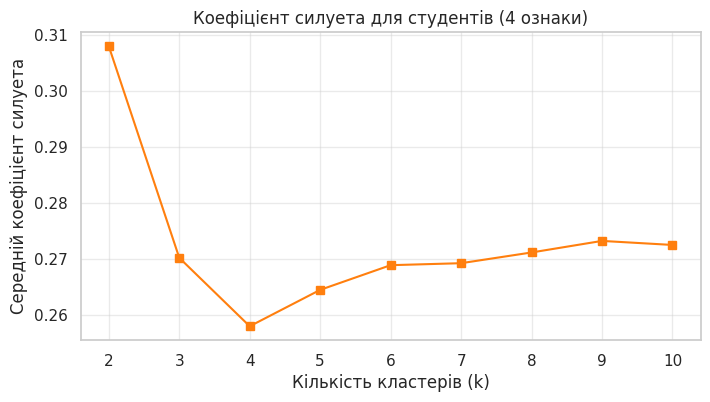

In [21]:
sil_stud = []
k_vals_2_10 = range(2, 11)

for k in k_vals_2_10:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_stud_4_scaled)
    sil_stud.append(silhouette_score(X_stud_4_scaled, labels))

plt.figure(figsize=(8, 4))
plt.plot(k_vals_2_10, sil_stud, marker="s", color="tab:orange")
plt.title("Коефіцієнт силуета для студентів (4 ознаки)")
plt.xlabel("Кількість кластерів (k)")
plt.ylabel("Середній коефіцієнт силуета")
plt.xticks(k_vals_2_10)
plt.grid(True, alpha=0.4)
plt.show()

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [22]:
!pip install -q kneed yellowbrick

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [23]:
import numpy as np
from sklearn.decomposition import PCA
from kneed import KneeLocator

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [24]:
X_pca_raw = df.drop(columns=["StudentID", "GradeClass"])
print("Кількість ознак для PCA:", X_pca_raw.shape[1])

Кількість ознак для PCA: 13


**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [25]:
scaler_pca = StandardScaler()
X_pca_scaled = scaler_pca.fit_transform(X_pca_raw)

pca_full = PCA()
pca_full.fit(X_pca_scaled)

explained_var_ratio = pca_full.explained_variance_ratio_
for idx, var in enumerate(explained_var_ratio, start=1):
    print(f"PC{idx}: {var:.4f}")

PC1: 0.1525
PC2: 0.0861
PC3: 0.0827
PC4: 0.0807
PC5: 0.0786
PC6: 0.0779
PC7: 0.0763
PC8: 0.0760
PC9: 0.0744
PC10: 0.0738
PC11: 0.0717
PC12: 0.0675
PC13: 0.0018


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

Визначена кількість головних компонент (точка ліктя): 2


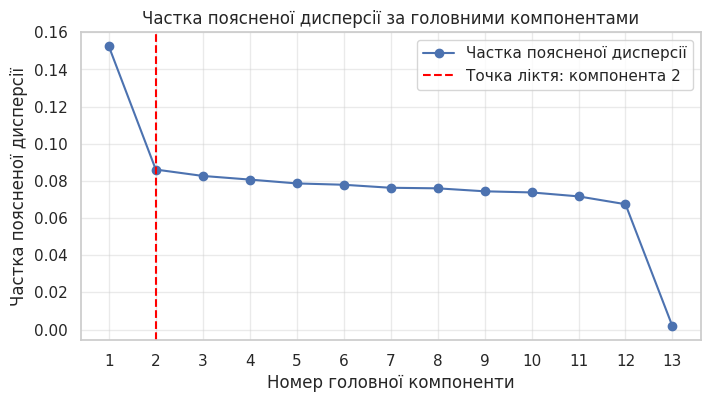

In [26]:
comp_numbers = np.arange(1, len(explained_var_ratio) + 1)

knee = KneeLocator(
    comp_numbers,
    explained_var_ratio,
    curve="convex",
    direction="decreasing"
)

n_components = int(knee.elbow) if knee.elbow is not None else 2
print(f"Визначена кількість головних компонент (точка ліктя): {n_components}")

plt.figure(figsize=(8, 4))
plt.plot(comp_numbers, explained_var_ratio, marker="o", label="Частка поясненої дисперсії")
plt.axvline(x=n_components, color="red", linestyle="--", label=f"Точка ліктя: компонента {n_components}")
plt.title("Частка поясненої дисперсії за головними компонентами")
plt.xlabel("Номер головної компоненти")
plt.ylabel("Частка поясненої дисперсії")
plt.xticks(comp_numbers)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

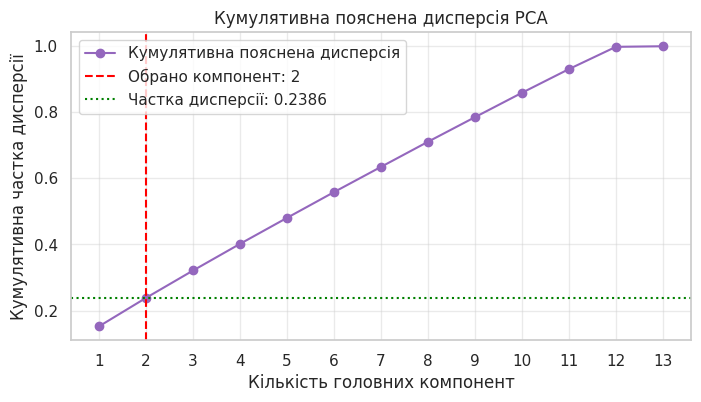

Фактична кумулятивна частка дисперсії для 2 компонент: 0.2386 (23.86%)
Форма перетворених даних після PCA: (2392, 2)


In [27]:
cum_var_ratio = np.cumsum(explained_var_ratio)
actual_cum_var = cum_var_ratio[n_components - 1]

plt.figure(figsize=(8, 4))
plt.plot(comp_numbers, cum_var_ratio, marker="o", color="tab:purple", label="Кумулятивна пояснена дисперсія")
plt.axvline(x=n_components, color="red", linestyle="--", label=f"Обрано компонент: {n_components}")
plt.axhline(y=actual_cum_var, color="green", linestyle=":", label=f"Частка дисперсії: {actual_cum_var:.4f}")
plt.title("Кумулятивна пояснена дисперсія PCA")
plt.xlabel("Кількість головних компонент")
plt.ylabel("Кумулятивна частка дисперсії")
plt.xticks(comp_numbers)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

print(f"Фактична кумулятивна частка дисперсії для {n_components} компонент: {actual_cum_var:.4f} ({actual_cum_var * 100:.2f}%)")

pca_opt = PCA(n_components=n_components)
X_pca_transformed = pca_opt.fit_transform(X_pca_scaled)
print("Форма перетворених даних після PCA:", X_pca_transformed.shape)

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [28]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

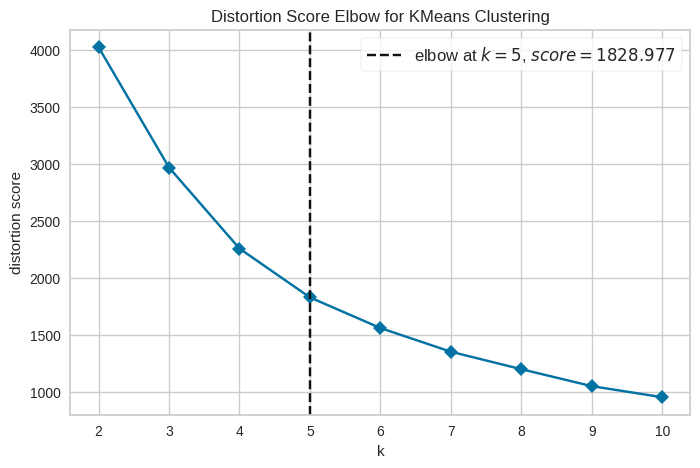

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [29]:
plt.figure(figsize=(8, 5))
visualizer = KElbowVisualizer(
    KMeans(random_state=42, n_init=10),
    k=(2, 11),
    timings=False
)
visualizer.fit(X_pca_transformed)
visualizer.show()

## Висновки

Порівняння способів визначення кількості кластерів: метод ліктя (візуальний за графіком WCSS та автоматичний через KElbowVisualizer) шукає точку перегину, після якої зменшення внутрішньокластерної дисперсії сповільнюється, тоді як коефіцієнт силуета оцінює компактність і відокремленість кластерів (чим ближче до 1, тим чіткіший поділ). На наборі Iris обидва підходи підтверджують вибір $k=2$, а на даних студентів дають орієнтир щодо кількості однорідних груп за навчальними показниками.Різниця між класифікацією та кластеризацією (Завдання 2): у задачі класифікації використовується відома цільова мітка GradeClass (навчання з учителем), і моделі (Random Forest, Logistic Regression, SVM) навчаються передбачати оцінку успішності на тестових даних (найкращу модель обрано за CV Accuracy). У задачі кластеризації цільова змінна GradeClass не використовується (навчання без учителя) — алгоритм K-Means самостійно групує студентів за подібністю їхніх характеристик.Застосування PCA: для всіх ознак (без StudentID і GradeClass) за допомогою KneeLocator автоматично визначено оптимальну кількість головних компонент n_components (значення виведено вище) та обчислено фактичну кумулятивну частку поясненої дисперсії, після чого на зниженому просторі ознак побудовано графік ліктя через KElbowVisualizer.